# Example of the aitlas toolbox in the context of multi label image classification

## Import the required packages

In [ ]:
from aitlas.datasets import WHDLDMultilabelDataset
from aitlas.models import ResNet50MultiLabel
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor
from aitlas.utils import image_loader

## Load the dataset

In [7]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/Images/",
    "csv_file": "/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/whdld_multilabel_train.csv",
}
dataset = WHDLDMultilabelDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 2951


## Show images from the dataset

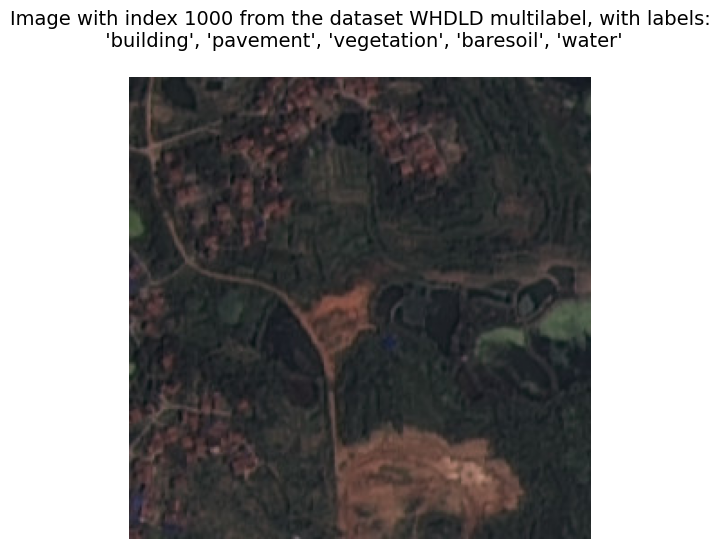

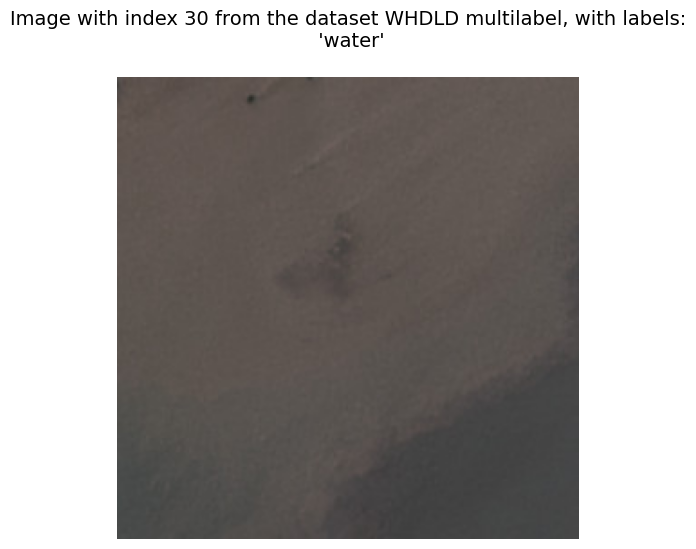

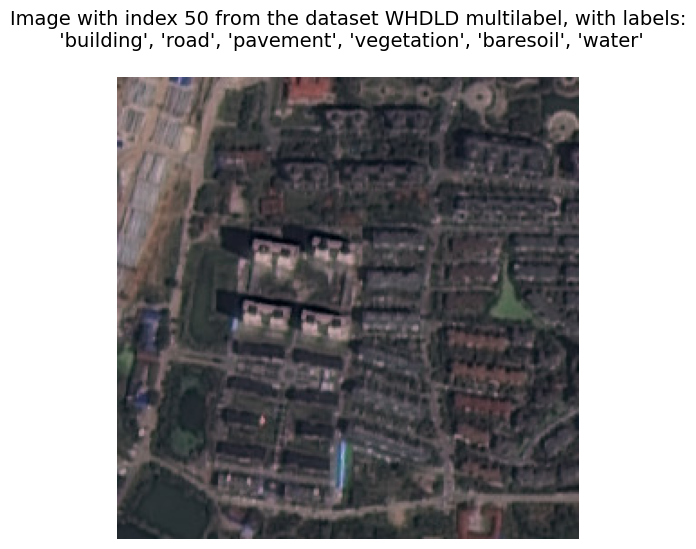

In [8]:
fig1 = dataset.show_image(1000)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(50)

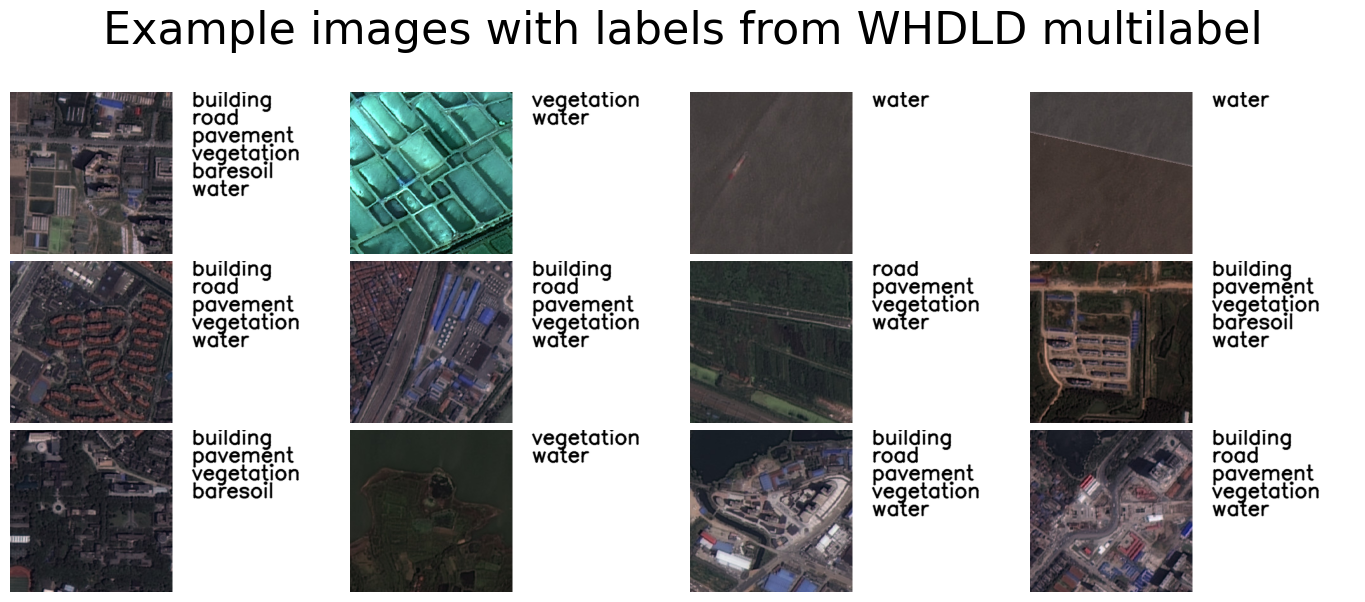

In [9]:
fig4 = dataset.show_batch(12)

## Inspect the data

In [10]:
dataset.show_samples()

,IMAGE\LABEL,building,road,pavement,vegetation,baresoil,water
0,wh0003,1,0,0,1,0,1
1,wh0004,0,0,0,1,0,1
2,wh0005,0,0,0,1,0,1
3,wh0009,0,0,0,1,0,1
4,wh0013,1,0,1,1,0,1
5,wh0014,0,0,0,1,0,1
6,wh0015,0,0,1,1,0,1
7,wh0016,0,0,1,1,0,1
8,wh0017,0,0,0,1,0,1
9,wh0018,1,1,1,1,0,1


In [11]:
dataset.data_distribution_table()

,Label,Count
1,building,2233
2,road,1897
3,pavement,2329
4,vegetation,2779
5,baresoil,2123
6,water,2332


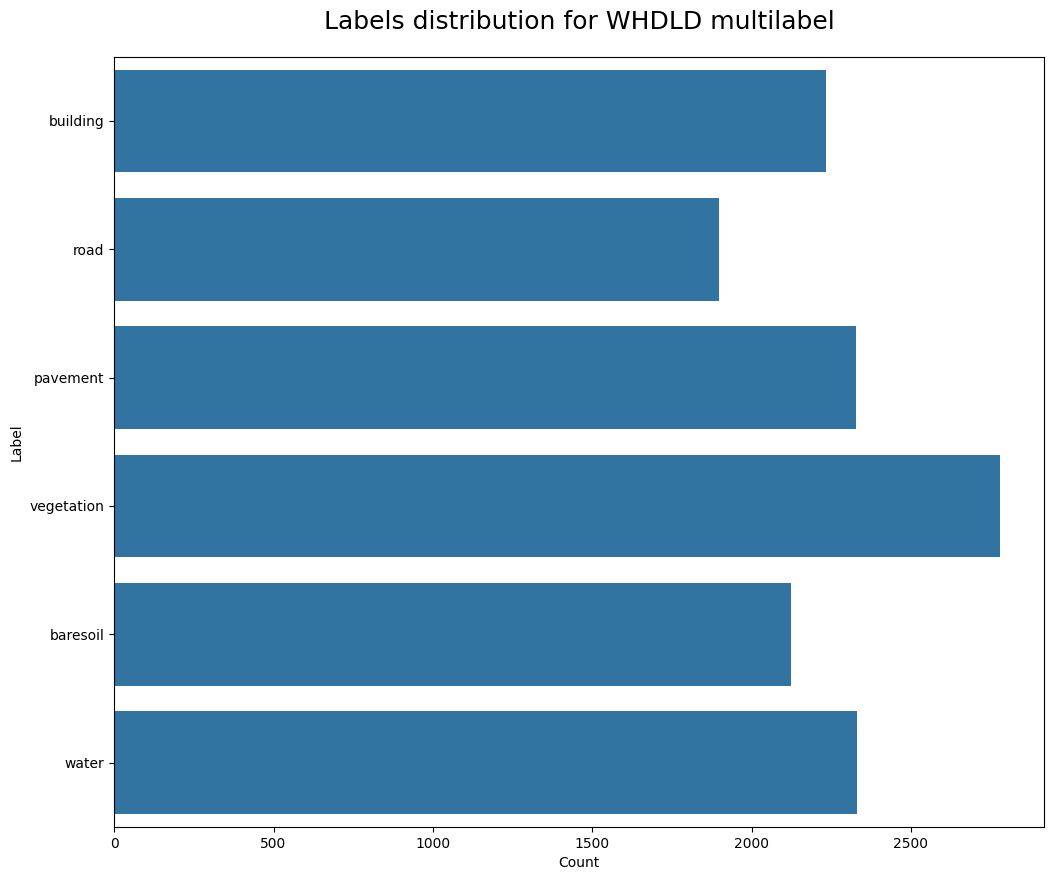

In [12]:
fig = dataset.data_distribution_barchart()

## Load train and test splits

In [13]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/Images/",
    "csv_file": "/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/whdld_multilabel_train.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = WHDLDMultilabelDataset(train_dataset_config)
train_dataset.transform = ResizeCenterCropFlipHVToTensor() 

test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/Images/",
    "csv_file": "/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/whdld_multilabel_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = WHDLDMultilabelDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2951, 979)

## Setup and create the model for training

In [16]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/whdld_multilabel/"
model_config = {
    "num_classes": 6, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5, 
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = ResNet50MultiLabel(model_config)
model.prepare()

## Training and evaluation

In [17]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2026-03-30 12:30:20,184 INFO Starting training.
training: 100%|██████████| 185/185 [00:06<00:00, 27.68it/s]
2026-03-30 12:30:26,916 INFO epoch: 1, time: 6, loss:  0.46528
testing on train set: 100%|██████████| 185/185 [00:02<00:00, 73.95it/s]
2026-03-30 12:30:29,961 INFO Accuracy:0.8838811702247825, Accuracy per Class:[0.91460522 0.84683158 0.87495764 0.9766181  0.8051508  0.88512369], Precision Micro:0.9118125840469955, Precision Macro:0.9095801228219557, Precision Weighted:0.915469293321907, Precision per Class:[0.95290352 0.8468555  0.93057996 0.99452555 0.81514658 0.91746963], Recall Micro:0.9408456875775943, Recall Macro:0.9392079820143171, Recall Weighted:0.9408456875775943, Recall per Class:[0.93327362 0.9298893  0.90940318 0.98056855 0.94300518 0.93910806], F1_score Micro:0.926101646179282, F1_score Macro:0.9232292508587516, F1_score Weighted:0.927099008522831, F1_score per Class:[0.94298643 0.88643216 0.91986971 0.98749774 0.87442673 0.92816275]
testing on validation set: 100%

0.09142363384878054

## Predictions

2026-03-30 12:33:02,333 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/whdld_multilabel/checkpoint.pth.tar
2026-03-30 12:33:02,484 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/whdld_multilabel/checkpoint.pth.tar at epoch 11


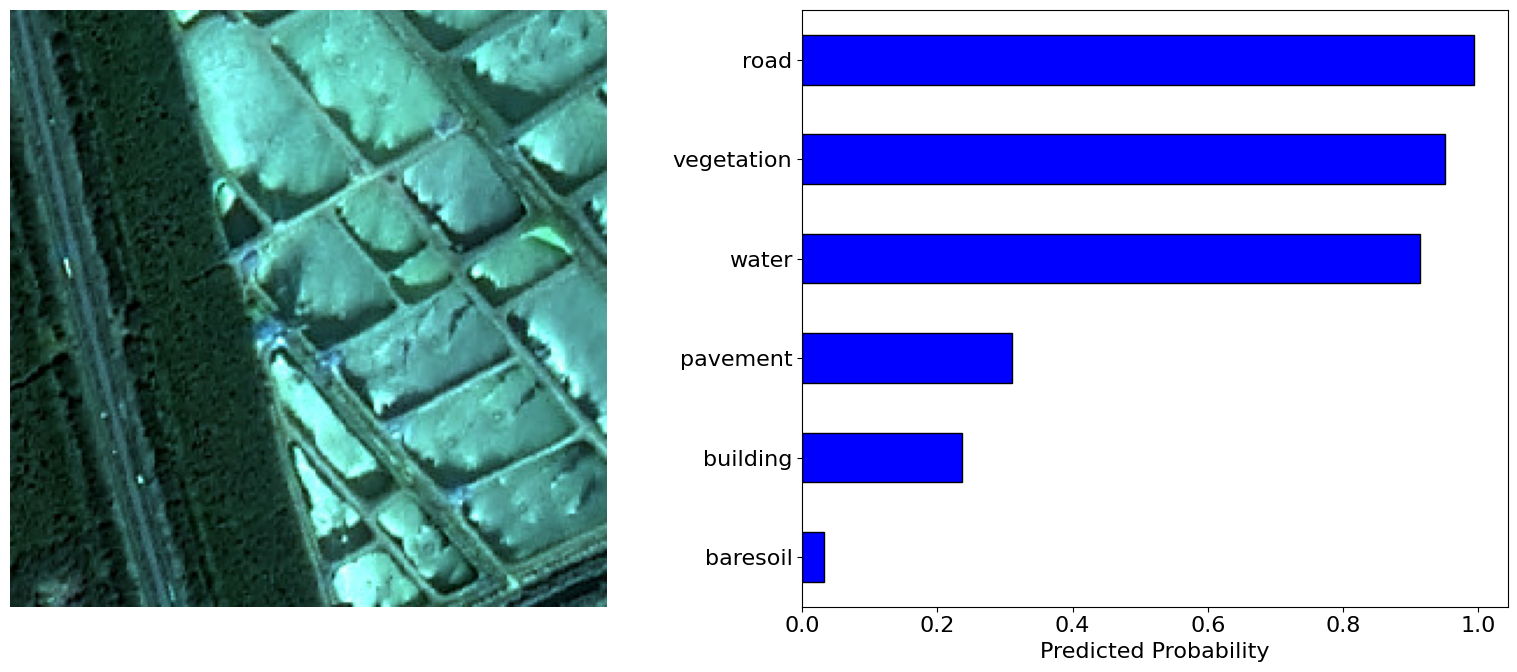

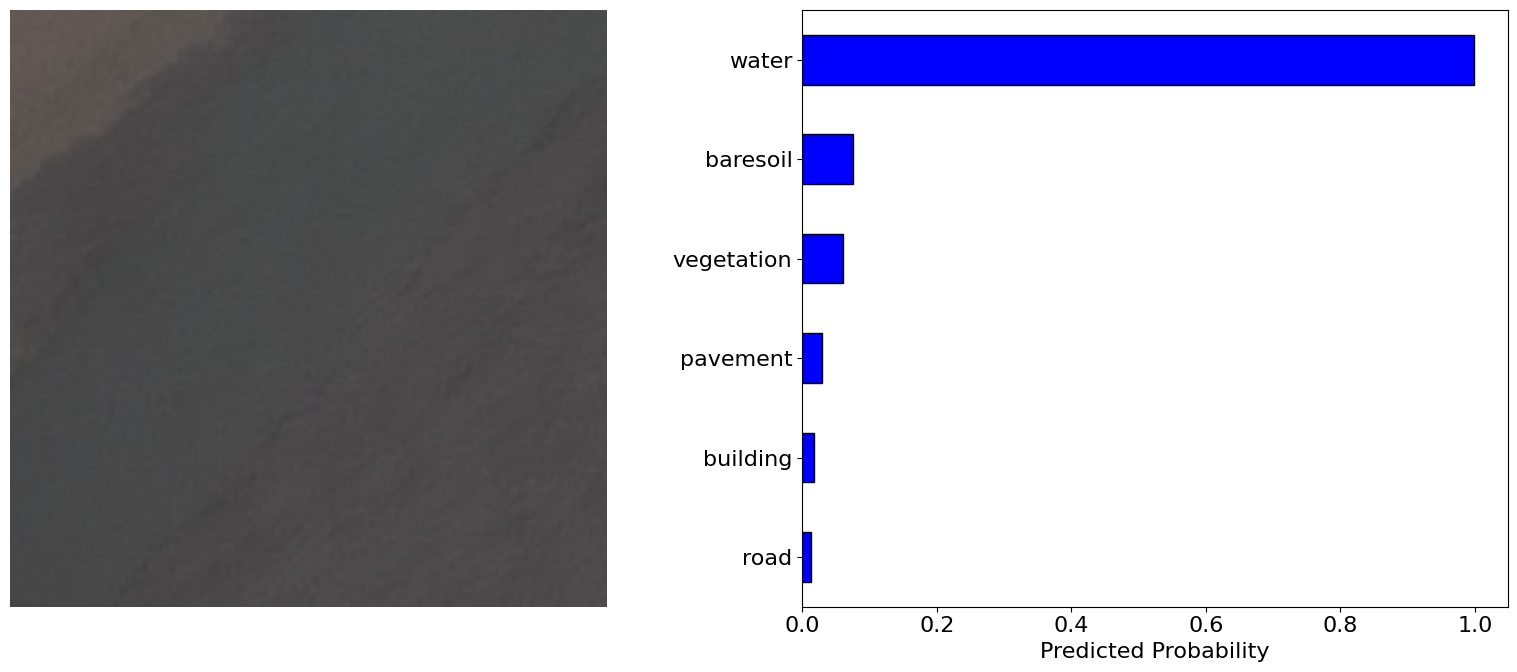

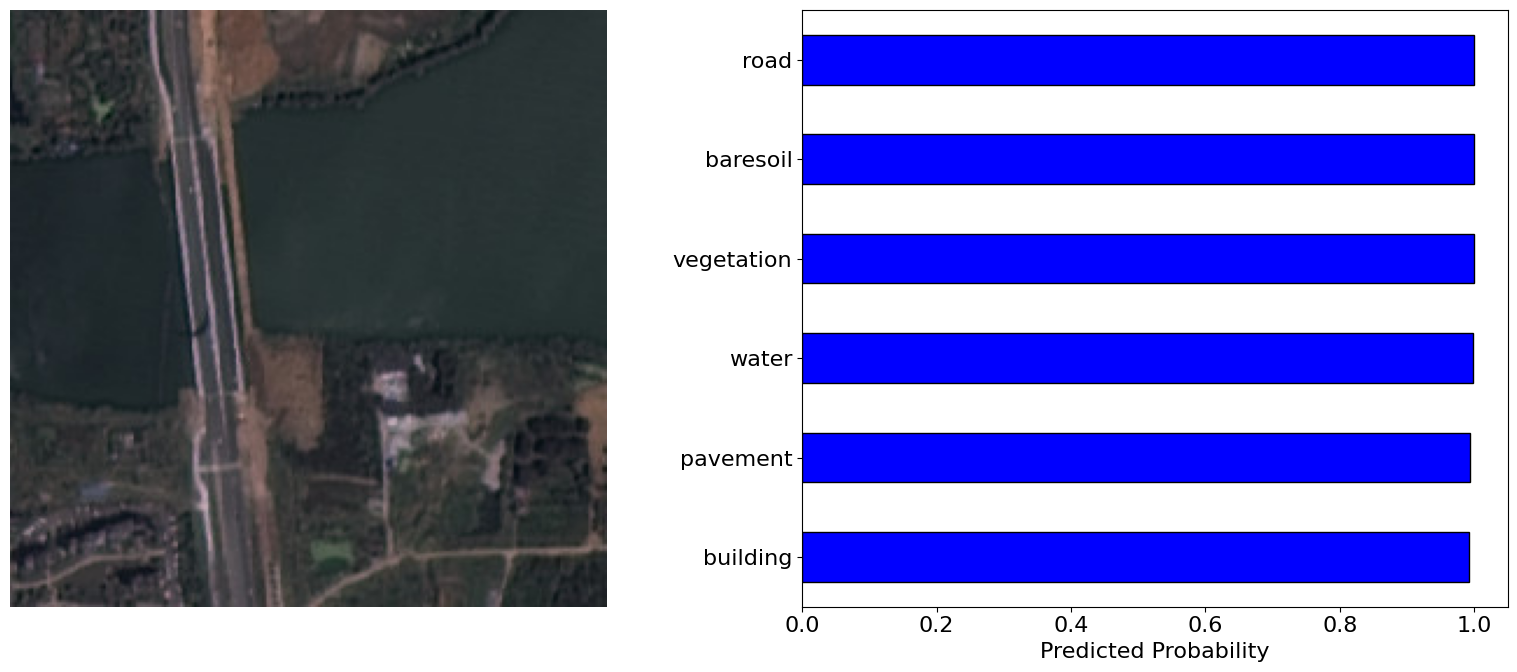

In [19]:
model_path = "/home/dragik/data/FAIR_EO/experiments/whdld_multilabel/checkpoint.pth.tar"
labels = ["building","road","pavement","vegetation","baresoil","water"]
transform = ResizeCenterCropToTensor()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/Images/wh0001.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/Images/wh0061.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/whdld_multilabel/WHDLD/Images/wh0154.jpg')
fig = model.predict_image(image, labels, transform)